<a href="https://colab.research.google.com/github/xudavid715-cloud/econ3916-lab19-random-forests-branch-main-commit-message-Lab-19-submission/blob/main/lab_ch19_guided_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 19: Tree-Based Models — Random Forests
## ECON 3916: Applied Machine Learning for Economists
### Guided Construction Lab | 40 min Core + 55 min AI + 25 min Extension

---

**Learning Objectives:**
- See a single tree memorise its training rows, and a forest of such trees generalise
- Compare a forest with OLS and Ridge on the same split, and read its out-of-bag score
- Compare impurity (MDI) and permutation importance, and explain why they disagree
- Tune `max_depth` and `max_features` by cross-validation
- Write your own prompt for a feature-importance chart, and check the AI's numbers against the lab's

**Dataset:** California Housing (scikit-learn): 20,640 block groups, 8 features, and the median
house value in units of $100,000. You have used it since Lab 4.

**Prerequisites:** the Part 0 sections of Labs 1-5, and the labs before this one. Lab 16's
pipeline with `StandardScaler` and Lab 15's bias-variance curve are used again here.

**How this lab works:** Parts 1-3 are GUIDED: run each cell as it is, then answer the questions.
The AI-Assisted Expansion is required: as in Lab 16, you write the prompt yourself. The Extension
is optional.

Plan on about 1 hour 55 minutes for the required work: setup, Parts 1-3, the AI-Assisted Expansion, and the README and submission.

AI in the manual parts: you may ask Colab to explain an error or a line of code (click Explain error, or select a line and ask Gemini to explain it). Do not ask it to write or fix code, and turn off AI code completion while you work on those parts. AI-assisted coding is allowed only where this lab says so.


---

> ### What you write, and what you run
>
> **You write:**
*   The answers to the interpretation questions, in text cells: two after Part 1, and one each after Parts 2 and 3.
The AI-Assisted Expansion: your own prompt, from scratch, asking AI for a

*  The AI-Assisted Expansion: your own prompt, from scratch, asking AI for a function that charts a model's feature importances and gives them back as a table; a revised prompt for round 2 (and round 3 if you need it); the AI's reply to each round, as a share link or the text; a short checking log; and two answers. Your prompts, the AI's replies, the log and the answers are what is graded, not the AI's code.



>
> **You run and read:** everything else. Setup and Parts 1-3 are working code to learn from. Read each cell before you run it, and make sure you can say what each line does. The check cells in the AI section: run them; you need not follow their code. The AI's function is pasted, not typed.
>
> **The Extension** (optional) has one guided cell, then a task with no starter code that you write in a new cell. The **README** is text only: the prompt at the end is for documentation, not code.

## Setup

The first line of the setup cell upgrades scikit-learn to 1.9 or later, because the way trees
are built changed in 1.9: with an older version, the tree and forest numbers in this notebook
differ in the third or fourth decimal. The cell prints your scikit-learn version. If it shows a version below 1.9, use **Runtime → Restart session** and run this cell again.

Every model in this lab is given `random_state=RANDOM_STATE`, so running a cell twice gives the
same numbers.

`fetch_california_housing()` downloads the data the first time (a few seconds) and returns it in
parts: `.data` holds the features, `.target` the house values and `.feature_names` the column
names. `pd.DataFrame(data.data, columns=...)` puts the features in a table with those names.
`train_test_split` keeps 20% of the rows (`test_size=0.2`) as test rows, as in Lab 12.

In [16]:
# GUIDED — run as-is
# Step 1: imports, and California Housing split into training and test rows
!pip install "scikit-learn>=1.9" -q

import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'scikit-learn {sklearn.__version__} (this lab\'s numbers assume 1.9 or later)')
print(f'Training set: {X_train.shape[0]} observations, {X_train.shape[1]} features')
print(f'Test set: {X_test.shape[0]} observations')
print(f'Features: {list(X.columns)}')

# savefig will not create a folder, and a fresh Colab session has no figures/ folder
Path("figures").mkdir(exist_ok=True)

scikit-learn 1.9.1 (this lab's numbers assume 1.9 or later)
Training set: 16512 observations, 8 features
Test set: 4128 observations
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Expected output:** 16512 training rows with 8 features, 4128 test rows, and the eight feature
names from `MedInc` (median income, in $10,000s) to `Longitude`.

**Run note.** This notebook ran with scikit-learn 1.9.1. The expected-output boxes below are the original handout's reference values. The answers and README use the values printed in this run.

## Part 1: Decision Tree vs. Random Forest vs. Ridge (GUIDED — 14 min)

We compare four models on the same rows. The question: does the forest's added complexity give
better predictions than simpler alternatives?

Step 2 fits them, each with `.fit(X, y)`, predictors first:
- a **single tree**, `DecisionTreeRegressor`, with no depth limit: it keeps splitting until it
  cannot;
- **OLS**, `LinearRegression`, as in Lab 12;
- **Ridge**, in a pipeline behind `StandardScaler`, as in Lab 16: the penalty falls evenly across
  the features only when they share one scale;
- a **random forest** of 100 trees, `RandomForestRegressor`. Each tree is grown on a bootstrap
  sample of the training rows, so it never sees about a third of them: its *out-of-bag* rows.
  `oob_score=True` asks the forest to score every training row using only the trees that never
  saw it.

Then it scores each model on the training rows and on the test rows. RMSE, the root of the mean
squared error, is in the target's units, $100,000s. The loop collects one dictionary per model,
and `pd.DataFrame(rows).set_index("Model")` turns the list into a table with one row per model.

In [17]:
# GUIDED — run as-is
# Step 2: four models on the same training rows, scored on both sets
tree = DecisionTreeRegressor(random_state=RANDOM_STATE)      # no depth limit
tree.fit(X_train, y_train)

ols = LinearRegression()
ols.fit(X_train, y_train)

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

rows = []
for name, model in [('Single Tree', tree), ('OLS', ols),
                    ('Ridge', ridge), ('Random Forest', rf)]:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred),
    })

results_df = pd.DataFrame(rows).set_index('Model')
print(results_df.round(4))

               Train RMSE  Test RMSE  Train R²  Test R²
Model                                                  
Single Tree        0.0000     0.7030    1.0000   0.6228
OLS                0.7197     0.7456    0.6126   0.5758
Ridge              0.7197     0.7456    0.6126   0.5758
Random Forest      0.1882     0.5060    0.9735   0.8046


**Expected output:**

| Model | Train RMSE | Test RMSE | Train R² | Test R² |
|---|---|---|---|---|
| Single Tree | 0.0000 | 0.7093 | 1.0000 | 0.6161 |
| OLS | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Ridge | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Random Forest | 0.1882 | 0.5063 | 0.9735 | 0.8044 |

Step 2, continued, looks inside the tree and the forest. `.get_n_leaves()` counts the tree's
final boxes: each leaf is one rectangle of feature space with one prediction, the mean of its
training rows. `rf.max_features` is how many features each split may choose from; `1.0` means
all of them. `.oob_score_` is the out-of-bag R². `results_df.loc[row, column]` reads one cell of
the table. In the prints, `:,` puts commas in the thousands and `:+.6f` shows six decimals with
the sign.

In [18]:
# GUIDED — run as-is
# Step 2, continued: inside the tree and the forest
print(f"single tree: {tree.get_n_leaves():,} leaves for {len(X_train):,} training rows")
print(f"features each split of the forest may choose from: max_features = {rf.max_features}")
print(f"forest out-of-bag R²: {rf.oob_score_:.4f}   "
      f"test R²: {results_df.loc['Random Forest', 'Test R²']:.4f}")

gap = results_df.loc['Ridge', 'Test R²'] - results_df.loc['OLS', 'Test R²']
print(f"Ridge test R² minus OLS test R²: {gap:+.6f}")

single tree: 15,860 leaves for 16,512 training rows
features each split of the forest may choose from: max_features = 1.0
forest out-of-bag R²: 0.8070   test R²: 0.8046
Ridge test R² minus OLS test R²: +0.000028


**Expected output:** 15,870 leaves for 16,512 training rows; `max_features = 1.0`; an
out-of-bag R² of 0.8069 beside a test R² of 0.8044; and Ridge minus OLS of +0.000028.

Three notes on those lines:
- `max_features = 1.0` is the default the lecture asked you to check: `RandomForestRegressor` lets
  every split choose from every feature unless you say otherwise, so Step 2's forest decorrelates
  its trees only through the bootstrap: it is bagging. Part 3 tries the alternatives.
- The out-of-bag R² never touched a test row, yet lands close to the test R²: each training row is
  scored only by the trees that never drew it, so it is a true held-out score. It is not exactly
  the test R² because the rows differ, and each row is scored by only about a third of the trees.
- The penalty gained Ridge essentially nothing here. With 16,512 training rows and only 8
  features, OLS has almost no variance for a penalty to remove; regularization pays when p is
  large relative to n, as in Lab 16 (p = 200, n = 105).

### Interpretation Questions

1. Which model has the largest gap between its train R² and its test R²? Use the leaf count to explain where that gap comes from.
2. The forest's test R² is 0.23 above Ridge's, with the same eight features. What does that say about how the features relate to house values?

1. The single tree has the largest gap. Its training R² is 1.0000, but its test R² is 0.6228, a drop of 0.3772. It grew 15,860 leaves for 16,512 training rows. With nearly one leaf per observation, it could match individual training values, including variation that did not repeat in the test set.
2. The forest explained about 23 percentage points more of the variation in held-out house values than Ridge (0.8046 versus 0.5758). Both saw the same eight features. The gain suggests that thresholds or interactions matter. For example, the relationship between income and predicted house value can vary by location in a forest, while this Ridge model assigns income one slope everywhere. The scores tell us about prediction, not what would happen if an area's income changed.

## Part 2: Feature Importance — MDI vs. Permutation (GUIDED — 14 min)

Random forests tell us which features matter most for prediction. But remember: **predictive
importance is not causal importance.** Step 3 measures it two ways, for Step 2's forest.

- **MDI** (mean decrease in impurity), `rf.feature_importances_`, comes free with training. Each
  split lowers the squared error inside its box; MDI adds up those drops for each feature, weighted
  by how many training rows reached the split, and scales them to sum to 1. A split near the root
  reaches most of the training rows, so its drop counts for a lot; a split deep in a tree reaches a
  few rows and counts for little, however much the predictions depend on it.
- **Permutation importance**, `permutation_importance(rf, X_test, y_test, n_repeats=10,
  random_state=RANDOM_STATE)`, uses the fitted forest and the test rows. It shuffles one column
  at a time, which breaks that feature's link with the outcome, and records how far the forest's
  test R² falls (R² is the score `permutation_importance` uses for a regressor unless told
  otherwise). It repeats each shuffle 10 times with different orders, seeded, and
  `.importances_mean` is the average fall.

`pd.Series(values, index=X.columns)` labels each number with its feature. The two Series become
the two columns of one table, sorted by permutation importance, largest first
(`ascending=False`).

In [19]:
# GUIDED — run as-is
# Step 3: impurity (MDI) and permutation importance for Step 2's forest
mdi_importance = pd.Series(rf.feature_importances_, index=X.columns)

perm_result = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE
)
perm_importance = pd.Series(perm_result.importances_mean, index=X.columns)

importance_table = pd.DataFrame({'MDI': mdi_importance, 'permutation': perm_importance})
print(importance_table.sort_values('permutation', ascending=False).round(4))

               MDI  permutation
MedInc      0.5250       0.7329
Latitude    0.0890       0.4427
Longitude   0.0885       0.3361
AveOccup    0.1384       0.2031
HouseAge    0.0546       0.0721
AveRooms    0.0442       0.0277
AveBedrms   0.0297       0.0095
Population  0.0307       0.0080


**Expected output:**

| | MDI | permutation |
|---|---|---|
| MedInc | 0.5250 | 0.7307 |
| Latitude | 0.0889 | 0.4465 |
| Longitude | 0.0886 | 0.3376 |
| AveOccup | 0.1384 | 0.2026 |
| HouseAge | 0.0547 | 0.0726 |
| AveRooms | 0.0442 | 0.0272 |
| AveBedrms | 0.0297 | 0.0091 |
| Population | 0.0306 | 0.0080 |

The AI-Assisted Expansion asks you to reproduce the permutation column with a function written
by AI.

Step 3, continued, draws both columns side by side. A horizontal bar chart (`.plot.barh`) draws
the first row at the bottom, so each Series is sorted smallest first to put the longest bar on
top.

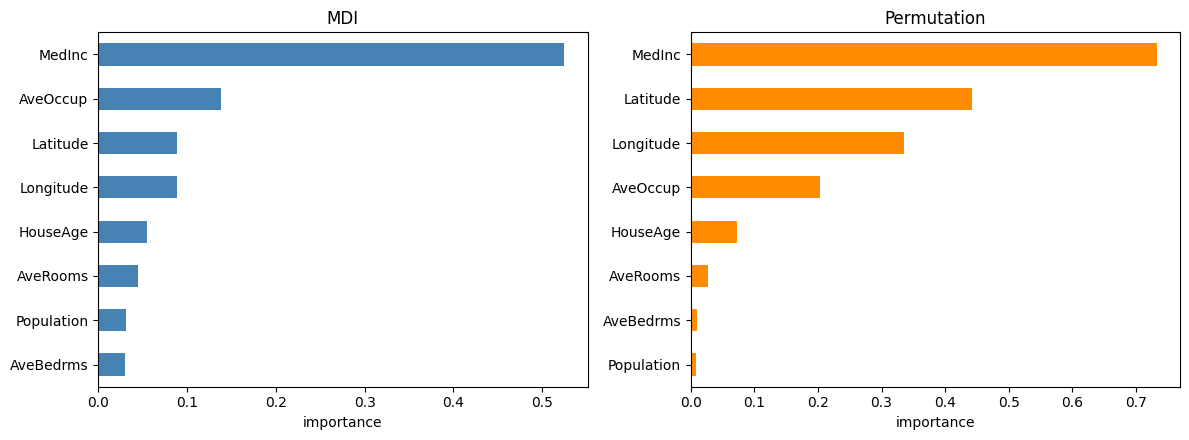

In [20]:
# GUIDED — run as-is
# Step 3, continued: the two measures side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

mdi_importance.sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('MDI')
axes[0].set_xlabel('importance')

perm_importance.sort_values().plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Permutation')
axes[1].set_xlabel('importance')

plt.tight_layout()
plt.savefig('figures/ch19_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretation Questions

1. Compare the two columns by rank, 1st to 8th in each, not by the raw numbers: MDI is scaled to sum to 1 and permutation is a fall in test R², so the two are on different scales. Which features does MDI rank higher than permutation does, and what do they have in common? Which does it rank lower, and why?

| Feature | MDI rank | Permutation rank |
|---|---:|---:|
| MedInc | 1 | 1 |
| AveOccup | 2 | 4 |
| Latitude | 3 | 2 |
| Longitude | 4 | 3 |
| HouseAge | 5 | 5 |
| AveRooms | 6 | 6 |
| Population | 7 | 8 |
| AveBedrms | 8 | 7 |

MDI moves **AveOccup** and **Population** up. Both are numeric measures of how people are distributed across a block group, with many possible split points. Their splits earn a larger share of the training-error reductions relative to other features than their shuffles earn in the test ranking. Population barely moves test R² when shuffled.

MDI moves **Latitude, Longitude and AveBedrms** down. One coordinate split can leave very different neighborhoods together. Later splits on the other coordinate can locate a neighborhood more precisely, but each gets less MDI credit because fewer rows reach it. Shuffling a coordinate disrupts those combinations across the test set. AveBedrms only swaps places with Population. Their permutation scores are close (0.0095 and 0.0080), so that switch alone tells us little about their relative value.

## Part 3: Hyperparameter Tuning (GUIDED — 12 min)

Step 4 tunes the forest by cross-validation, with `GridSearchCV`. It fits a fresh forest for every
combination in `param_grid`, on every fold, and keeps the combination with the best average score.
- `max_depth`: 10 levels, or `None`, no limit (as in Step 2).
- `max_features`: how many of the 8 features each split may choose from. `'sqrt'` is √8, rounded
  down to 2; `0.5` is half of them, 4. Step 2 used all 8.
- `cv=3`: three folds, as in Lab 15.
- scikit-learn always keeps the *largest* score, so to minimise the error it scores by minus the
  MSE, `'neg_mean_squared_error'`. `np.sqrt(-score)` turns it back into an RMSE.
- `n_jobs=-1` uses every processor core.

Count the work before you run it: 2 × 2 = 4 combinations × 3 folds = 12 forests, each on about
11,000 rows, plus one more to refit the winner on all the training rows: 13. That takes about a
minute on Colab. A 3 × 3 × 3 grid with 5 folds would be 136 forests, and you would still be
waiting when the lab ended.

After the search, `.best_params_` is the winning combination and `.best_score_` its score.
`.best_estimator_` is a forest with those settings, refitted on all the training rows.
`.cv_results_` holds every combination's settings (`'params'`) and average score
(`'mean_test_score'`), in the same order; `zip` walks through the two lists side by side.
`str()` turns `None` into text, and `:<5` left-aligns it in 5 characters, so the columns line up.

In [21]:
# GUIDED — run as-is (about a minute: 13 forests)
# Step 4: tune max_depth and max_features by 3-fold cross-validation
param_grid = {
    'n_estimators': [100],
    'max_depth': [10, None],
    'max_features': ['sqrt', 0.5],
}
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

for params, score in zip(grid_search.cv_results_['params'],
                         grid_search.cv_results_['mean_test_score']):
    print(f"max_depth = {str(params['max_depth']):<5} max_features = "
          f"{str(params['max_features']):<5} CV RMSE {np.sqrt(-score):.4f}")

print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-grid_search.best_score_):.4f}')

best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, best_pred))
test_r2 = r2_score(y_test, best_pred)
print(f'Tuned RF — Test RMSE: {test_rmse:.4f}, Test R²: {test_r2:.4f}')

max_depth = 10    max_features = sqrt  CV RMSE 0.5525
max_depth = 10    max_features = 0.5   CV RMSE 0.5383
max_depth = None  max_features = sqrt  CV RMSE 0.5068
max_depth = None  max_features = 0.5   CV RMSE 0.5034

Best parameters: {'max_depth': None, 'max_features': 0.5, 'n_estimators': 100}
Best CV RMSE: 0.5034
Tuned RF — Test RMSE: 0.4998, Test R²: 0.8094


**Expected output:** CV RMSEs of 0.5522 (depth 10, `'sqrt'`), 0.5382 (depth 10, 0.5), 0.5066
(no limit, `'sqrt'`) and 0.5048 (no limit, 0.5). Then `Best parameters: {'max_depth': None,
'max_features': 0.5, 'n_estimators': 100}`, `Best CV RMSE: 0.5048`, and
`Tuned RF — Test RMSE: 0.4969, Test R²: 0.8116`.

### Interpretation Questions

1. Within the grid, which setting mattered more? Relative to Step 2's forest, which setting did the tuned forest actually change?

Within the grid, depth mattered more. Removing the depth cap lowered CV RMSE by 0.0457 with two candidate features per split and by 0.0349 with four. Increasing the candidate count from two to four lowered CV RMSE by only 0.0142 at depth 10 and 0.0034 without a cap. Compared with Step 2, the winner kept 100 trees and unlimited depth. It changed only the number of candidate features per split, from all eight to four (`max_features=0.5`). Its test R² rose from 0.8046 to 0.8094.

---

## AI-Assisted Expansion: a feature-importance chart, your prompt, checked by you

Step 3 took two cells to compute permutation importance and chart it. A function that does both
for any fitted model, and hands back the numbers as a table, is code you would reuse in every
project, and quick for AI to write. It also makes every choice your prompt leaves out, and most of
those choices change the numbers. As in Lab 16, no prompt is given: you write it.

**The target.** Given Step 2's forest and the test rows, your function must reproduce Step 3's
permutation column, all eight features, from **MedInc 0.7307** to **Population 0.0080**. Asked for
the top 3, it must give back MedInc, Latitude and Longitude, in that order, with the same numbers.

**What the check calls.** `importance_chart(model, X, y, k)`: an already fitted `model`, a
DataFrame `X`, the outcome `y`, and `k`, the number of features to keep. It draws a horizontal bar
chart of the top `k` and gives back a pandas DataFrame with columns `feature` and `importance`,
largest first. The check runs it on a copy of Step 2's `rf` with `X_test` and `y_test`, at `k = 8`
and `k = 3`, and counts the forests it fits while it runs (Step 3 fitted none). Then it runs it once
more, at `k = 4`, on a model and rows it has not seen: a tree 6 levels deep, fitted on the training
rows with the columns in reverse order, and the first 500 test rows, beside `permutation_importance`
run on that tree directly. A function that uses the notebook's `rf`, `X_test`, `y_test` or feature
names instead of its own arguments fails there.

**What a good prompt states.** Step 3 and the paragraph above hold every answer.
- the function's name, its arguments in order and their types, and what it gives back;
- the model: what it is, and that it arrives already fitted;
- which importance, and every setting that changes its numbers;
- how the top `k` are picked and sorted;
- the chart: its type, its labels, and which bar goes on top;
- what to leave out (example data, a model of its own), and a comment on each line.

**What to do**
1. Write your round 1 prompt in the cell below and send it, exactly as written, to Claude
   ([claude.northeastern.edu](https://claude.northeastern.edu)) or ChatGPT, in a new chat.
2. Put the AI's reply in the reply cell under your prompt: the chat's share link, or, if your chat
   cannot make one, the whole reply copied in as text. The conversation is graded with your prompt.
3. Read the reply before you run anything. Paste only the function into the round 1 code cell, and
   run the check below it.
4. If a line says `NO`, find the choice in the function that caused it, state that choice in a
   round 2 prompt, and put the reply and the new function in the round 2 cells. A third round goes
   in the round 3 cells under them: new cells, so round 2's function and its check stay in your
   notebook as they ran. Stop when every line says `yes` and you can explain each line, or when
   you decide to stop.
5. If everything says `yes` in round 1, use round 2 to state one choice your prompt never asked
   for, and check that it still matches.
6. Fill in the checking log and answer the two questions. Those, your prompts and the AI's replies
   are graded, not the code.

**Reading the check.** For each `k` it prints Step 3's features in order beside the AI's, then one
line per feature: your number, the AI's, `same?`, and the % apart. Same forest, same rows, same
session: a correct function agrees in every printed digit, whether the rows arrive as a DataFrame
or an array and however many processor cores do the work. There is no allowed gap: a `NO` beside
the same printed digits, with a tiny % apart, means the function rounds its numbers. The last block
compares the function with `permutation_importance` on the other tree (its chart appears too). When every line says `yes`,
the check ends with a line that says so. It does not read the chart: compare its bars with the
table yourself. Each check runs the function twice on all 4,128 test rows, so it takes about as
long as Step 3 twice over: up to a minute on Colab.

Keep the function's name and argument order. If the AI also wrote example data or fitted its own
model, leave that out: it can replace the lab's.

In [22]:
# GUIDED — run as-is (you need not follow this code; the cells below use it)
# The check, as a function: the cells below run it once for each round.
# It saves the forest, the test rows and Step 3's numbers now, before anything is pasted.
import copy
try:
    from sklearn.ensemble._forest import BaseForest     # the class every scikit-learn forest builds on
except ImportError:                                     # if a later release moves it
    BaseForest = RandomForestRegressor

# Step 1's split, rebuilt from the data and the seed: a later cell that reuses the names is caught
_d = fetch_california_housing()
step1_split = train_test_split(pd.DataFrame(_d.data, columns=_d.feature_names), _d.target,
                               test_size=0.2, random_state=RANDOM_STATE)

PROBLEMS = {
    "split": "X_train, X_test, y_train or y_test no longer hold Step 1's split: a cell run after "
             "Step 1 gave those names new data. Usually that is the Extension, if it split with Step 1's "
             "names (it needs its own, such as X_test_c), or pasted code that defined them. Use new "
             "names there, then rerun the notebook from the top (Runtime → Run all).",
    "rf": "rf is no longer Step 2's forest: a cell run after Step 2 gave the name another model, or "
          "refitted it. Usually that is the Extension, if it called its classifier rf (it needs its own "
          "name, such as rf_clf), or pasted code that fitted a model. Use new names there, then rerun "
          "the notebook from the top (Runtime → Run all).",
    "step3": "Step 3's table was made with another forest than the rf you have now. Rerun the notebook "
             "from the top (Runtime → Run all).",
}


def lab_data_problem():
    """None if the split, rf and Step 3's table are still Steps 1-3's; otherwise which one changed."""
    X_tr, X_te, y_tr, y_te = step1_split
    # try runs the lines under it; if they raise an error (say a name is gone), except runs instead
    try:
        if not (X_train.equals(X_tr) and X_test.equals(X_te)
                and np.array_equal(y_train, y_tr) and np.array_equal(y_test, y_te)):
            return "split"
    except Exception:
        return "split"
    try:
        # Step 2's settings, and its out-of-bag score recomputed from Step 1's training outcome
        if not (type(rf) is RandomForestRegressor and rf.n_estimators == 100
                and rf.random_state == RANDOM_STATE and rf.max_features == 1.0
                and np.isclose(r2_score(y_tr, rf.oob_prediction_), rf.oob_score_, rtol=1e-12, atol=0)):
            return "rf"
    except Exception:
        return "rf"
    try:
        if not np.allclose(mdi_importance.values, rf.feature_importances_):
            return "step3"
    except Exception:
        return "step3"
    return None


saved_rf, saved_X, saved_y = rf, X_test.copy(), y_test.copy()
saved_perm = perm_importance.sort_values(ascending=False)     # Step 3's column, largest first

# a model and rows the function has not seen: a 6-level tree on the columns in reverse order
other_cols = list(X_test.columns)[::-1]
other_model = DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
other_model.fit(step1_split[0][other_cols], step1_split[2])
other_X, other_y = step1_split[1][other_cols].iloc[:500], step1_split[3][:500]
other_perm = pd.Series(permutation_importance(other_model, other_X, other_y, n_repeats=10,
                                              random_state=RANDOM_STATE).importances_mean,
                       index=other_cols).sort_values(ascending=False)


def show_pair(label, mine, ai):
    """One line: your number, the AI's, whether they agree, and how far apart they are."""
    # rtol=1e-9: equal to about 9 significant digits, so only rounding inside the computer passes
    same = "yes" if np.isclose(mine, ai, rtol=1e-9, atol=0) else "NO"
    pct = 100 * (ai - mine) / abs(mine)
    # a gap under 1%: sign and 2 significant digits, so a tiny one prints like +9.6e-06;
    # otherwise a whole number with its sign, like -200
    apart = f"{pct:+.2g}" if abs(pct) < 1 else f"{pct:+.0f}"
    print(f"  {label:<24}{mine:>10.4f}{ai:>10.4f}{same:>7}{apart:>11}%")
    return same == "yes"


def describe(value):
    """What the function gave back, in a few words."""
    if isinstance(value, (pd.Series, np.ndarray, list, tuple)):
        shown = ", ".join(f"{v:.4f}" if isinstance(v, (int, float, np.number)) else type(v).__name__
                          for v in list(value)[:8])
        return f"a {type(value).__name__}: {shown}"
    return f"a {type(value).__name__}"


def as_table(result):
    """The DataFrame the function gave back, with lower-case column names, or None."""
    if isinstance(result, (tuple, list)):          # (table, chart) or (chart, table)
        tables = [r for r in result if isinstance(r, pd.DataFrame)]
        if tables:
            result = tables[0]
    if not isinstance(result, pd.DataFrame):
        return None
    table = result.rename(columns=lambda c: str(c).lower())
    if "feature" not in table.columns and str(table.index.name).lower() == "feature":
        table = table.reset_index().rename(columns=lambda c: str(c).lower())
    return table


def table_or_message(result, names):
    """The table, or None after saying why the check cannot read what the function gave back."""
    table = as_table(result)
    if table is not None and {"feature", "importance"} <= set(table.columns):
        return table
    if table is not None and "importance" in table.columns and set(map(str, table.index)) <= set(names):
        print("importance_chart gave back a DataFrame with a column named importance, but the feature "
              "names are in its index (the row labels), not in a column of their own.")
    else:
        shown = describe(result) if table is None else f"a DataFrame with columns {list(table.columns)}"
        print(f"importance_chart gave back {shown}.")
    print("The check needs a DataFrame with a column named feature and one named importance.")
    return None


def compare(whose, header, ref, table, k):
    """Print ref's top k beside the AI's rows; give back (every line yes?, a NO beside the same digits?)."""
    ai_names = [str(f) for f in table["feature"]]
    mine_names = list(ref.index[:k])
    print(f"  {whose} top {k}, in order : {', '.join(mine_names)}")
    print(f"  the AI's rows, in order : {', '.join(ai_names)}")
    all_yes = ai_names == mine_names
    print(f"  same features, same order? {'yes' if all_yes else 'NO'}")
    print(f"  {'':<24}{header:>10}{'AI':>10}{'same?':>7}{'% apart':>12}")
    same_digits = False
    for name in mine_names:
        if name not in ai_names:
            print(f"  {name:<24}{ref[name]:>10.4f}{'missing':>10}")
            all_yes = False
            continue
        try:
            ai_value = float(table["importance"][table["feature"].astype(str) == name].iloc[0])
        except Exception:
            print(f"  {name:<24}{ref[name]:>10.4f}   not a number")
            all_yes = False
            continue
        if not show_pair(name, ref[name], ai_value):
            all_yes = False
            same_digits = same_digits or f"{ref[name]:.4f}" == f"{ai_value:.4f}"
    if same_digits:
        print("  A NO beside the same printed digits: the numbers differ only after the 4th decimal. The "
              "usual cause is rounding inside the function (round, .round(4), a format string): give back "
              "the full numbers, and round only when you print.")
    return all_yes


def check_importance_chart(fn):
    """Run the AI's importance_chart on Step 2's forest and the test rows, then on another model."""
    problem = lab_data_problem()
    if problem:
        print(PROBLEMS[problem])
        return
    # callable(x) is True when x is a function that can be called
    if not callable(fn):
        print("importance_chart should be a function. Paste the function the AI wrote.")
        return
    real_fit = BaseForest.fit
    every_line_yes = True
    for k in (8, 3):
        fits = []

        def counting_fit(self, *args, **kwargs):
            fits.append(1)
            return real_fit(self, *args, **kwargs)

        BaseForest.fit = counting_fit        # every forest fitted during the call is counted
        try:
            # a copy of the forest and of the rows, so the function cannot change the lab's
            result = fn(copy.deepcopy(saved_rf), saved_X.copy(), saved_y.copy(), k)
        except Exception as err:
            print(f"With k = {k}, the AI's function stopped with an error. "
                  f"{type(err).__name__}: {err}")
            return
        finally:
            BaseForest.fit = real_fit
        table = table_or_message(result, saved_X.columns)
        if table is None:
            return
        print(f"\nk = {k}")
        every_line_yes &= compare("Step 3's", "Step 3", saved_perm, table, k)
        print(f"  {'forests fitted by it':<24}{0:>10}{len(fits):>10}"
              f"{'yes' if not fits else 'NO':>7}")
        every_line_yes &= not fits

    # once more, on a model and rows it has not seen, beside permutation_importance run directly
    k = 4
    print(f"\nAnother model and other rows, k = {k}: a 6-level tree, the columns in reverse order, "
          f"the first {len(other_X)} test rows")
    try:
        result = fn(copy.deepcopy(other_model), other_X.copy(), other_y.copy(), k)
    except Exception as err:
        print(f"  The AI's function stopped with an error. {type(err).__name__}: {err}")
        print("  It ran on Step 2's forest and the test rows, so look for a line that uses the notebook's "
              "rf, X_test, y_test or feature names instead of the function's own model, X and y.")
        return
    table = table_or_message(result, other_cols)
    if table is None:
        return
    every_line_yes &= compare("the direct run's", "direct", other_perm, table, k)
    try:
        ai = dict(zip(table["feature"].astype(str), table["importance"].astype(float)))
        if len(ai) == k and np.allclose(sorted(ai.values()), sorted(saved_perm.values[:k]), rtol=1e-9, atol=0):
            print("  These are Step 3's numbers, not this tree's: the function uses the notebook's rf, "
                  "X_test or y_test, not the model, X and y it is given.")
        elif (len(ai) == k
              and np.allclose(sorted(ai.values()), sorted(other_perm.values[:k]), rtol=1e-9, atol=0)
              and not all(n in other_perm.index and np.isclose(v, other_perm[n], rtol=1e-9, atol=0)
                          for n, v in ai.items())):
            print("  These are this tree's numbers, beside the wrong names: the function takes the names "
                  "from the notebook (data.feature_names, or X_test's columns), not from the X it is given.")
    except Exception:
        pass
    if every_line_yes:
        print("\nEvery line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest "
              "fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.")
    else:
        print("\nIf a line says NO, find out why before you trust the function.")


problem = lab_data_problem()
if problem:
    print(PROBLEMS[problem])



**Round 1 prompt**

Write only a Python function importance_chart(model, X, y, k). The inputs are a fitted scikit-learn regressor, a pandas DataFrame of evaluation features, its outcomes and an integer number of features. Use only these inputs. Measure permutation importance on all supplied rows with R², 10 repeats and random_state=42. Return an unrounded pandas DataFrame with columns feature and importance, sorted by mean decrease in R² from largest to smallest and limited to the first k rows. Draw a labeled horizontal bar chart with the largest bar at the top. Comment every line. Include no sample data, model fitting or example calls.

**Full AI reply**

```python
def importance_chart(model, X, y, k):  # Rank and plot the first k features by permutation importance.
    import matplotlib.pyplot as plt  # Draw the horizontal bar chart.
    import pandas as pd  # Build the labeled results table.
    from sklearn.inspection import permutation_importance  # Measure the score change after shuffling each feature.
    scores = permutation_importance(model, X, y, scoring="r2", n_repeats=10, random_state=42)  # Use every evaluation row for each repeat.
    ranking = pd.DataFrame({"feature": X.columns, "importance": scores.importances_mean})  # Preserve the unrounded mean decreases in R².
    ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)  # Keep the top k and preserve column order for ties.
    _, ax = plt.subplots()  # Create a separate chart for this ranking.
    ax.barh(ranking.index, ranking["importance"])  # Draw one horizontal bar per ranked feature.
    ax.set_yticks(ranking.index, labels=ranking["feature"])  # Label each bar with its feature name.
    ax.invert_yaxis()  # Put the highest-ranked feature at the top.
    ax.set(xlabel="Mean decrease in R²", ylabel="Feature", title="Permutation importance")  # Identify the metric and features.
    ax.figure.tight_layout()  # Leave room for the labels.
    plt.show()  # Display the completed chart.
    return ranking  # Return the unrounded top-k table.
```

In [23]:
def importance_chart(model, X, y, k):  # Rank and plot the first k features by permutation importance.
    import matplotlib.pyplot as plt  # Draw the horizontal bar chart.
    import pandas as pd  # Build the labeled results table.
    from sklearn.inspection import permutation_importance  # Measure the score change after shuffling each feature.
    scores = permutation_importance(model, X, y, scoring="r2", n_repeats=10, random_state=42)  # Use every evaluation row for each repeat.
    ranking = pd.DataFrame({"feature": X.columns, "importance": scores.importances_mean})  # Preserve the unrounded mean decreases in R².
    ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)  # Keep the top k and preserve column order for ties.
    _, ax = plt.subplots()  # Create a separate chart for this ranking.
    ax.barh(ranking.index, ranking["importance"])  # Draw one horizontal bar per ranked feature.
    ax.set_yticks(ranking.index, labels=ranking["feature"])  # Label each bar with its feature name.
    ax.invert_yaxis()  # Put the highest-ranked feature at the top.
    ax.set(xlabel="Mean decrease in R²", ylabel="Feature", title="Permutation importance")  # Identify the metric and features.
    ax.figure.tight_layout()  # Leave room for the labels.
    plt.show()  # Display the completed chart.
    return ranking  # Return the unrounded top-k table.


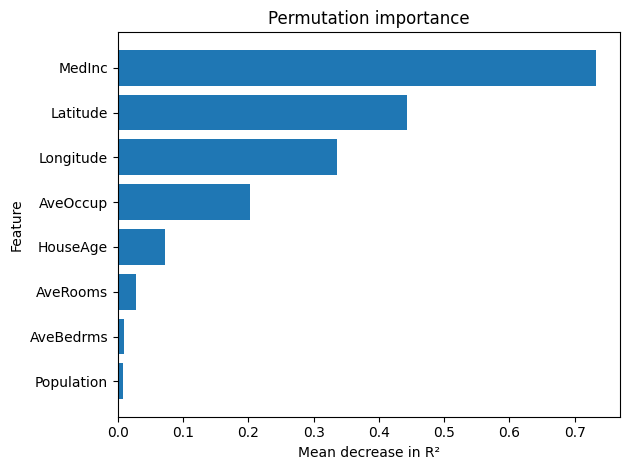


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


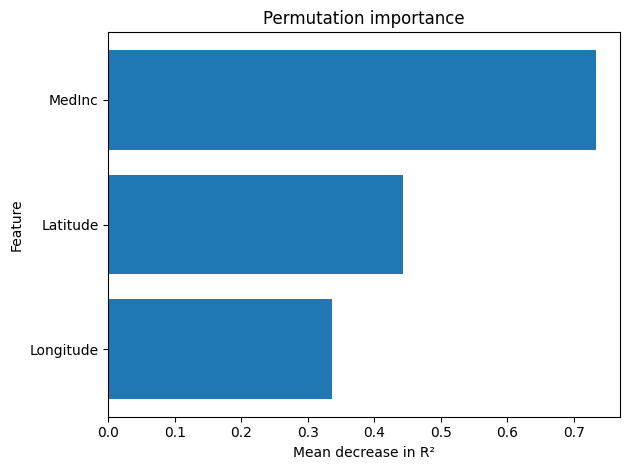


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


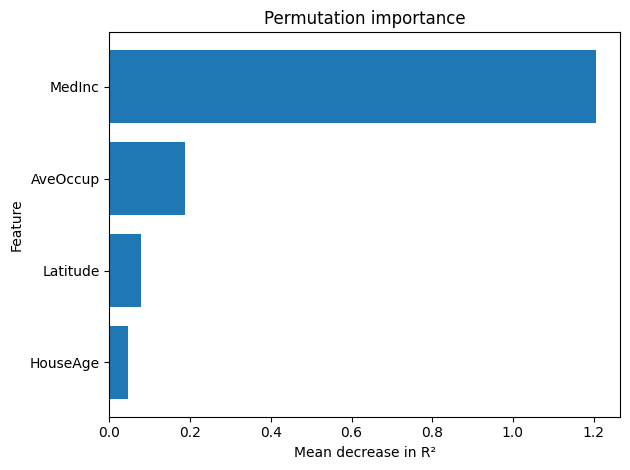

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [24]:
# CHECK — round 1
# To rerun this check, rerun the round 1 paste cell first: it checks whatever was pasted last
# globals() holds every name defined so far in this notebook
if "importance_chart" not in globals():
    print("Paste the AI's importance_chart function in the cell above first, keeping that name, "
          "and run that cell.")
else:
    importance_chart_r1 = importance_chart      # kept, so the round 2 check can tell the two apart
    check_importance_chart(importance_chart_r1)

**Round 2 prompt**

Keep the same function, scoring settings, output and chart. Round 1 chose stable sorting for ties without being asked. Keep that behavior explicitly so equally important features stay in the input column order. Also reject k outside 1 through the number of columns with a clear ValueError so a negative k cannot silently drop the last row. Return only the revised function, with a comment on each line.

**Full AI reply**

```python
def importance_chart(model, X, y, k):  # Rank and plot the k most important features.
    from numbers import Integral  # Accept Python and NumPy integer counts.
    import matplotlib.pyplot as plt  # Draw the horizontal bar chart.
    import pandas as pd  # Build the results table.
    from sklearn.inspection import permutation_importance  # Measure the effect of shuffling each feature.
    if isinstance(k, bool) or not isinstance(k, Integral) or not 1 <= k <= X.shape[1]:  # Require a valid integer feature count.
        raise ValueError(f"k must be an integer from 1 through the number of columns ({X.shape[1]}).")  # Report the allowed range.
    scores = permutation_importance(model, X, y, scoring="r2", n_repeats=10, random_state=42)  # Score ten shuffles per feature using all rows.
    ranking = pd.DataFrame({"feature": X.columns, "importance": scores.importances_mean})  # Preserve full precision and input column order.
    ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)  # Break ties by input column order.
    _, ax = plt.subplots()  # Create the chart.
    ax.barh(ranking.index, ranking["importance"])  # Draw a horizontal bar for each selected feature.
    ax.set_yticks(ranking.index, labels=ranking["feature"])  # Label the bars with feature names.
    ax.invert_yaxis()  # Put the highest-ranked feature at the top.
    ax.set(xlabel="Mean decrease in R²", ylabel="Feature", title="Permutation importance")  # Label both axes and the chart.
    ax.figure.tight_layout()  # Leave room for the labels.
    plt.show()  # Display the chart.
    return ranking  # Return the sorted, unrounded results.
```

In [25]:
def importance_chart(model, X, y, k):  # Rank and plot the k most important features.
    from numbers import Integral  # Accept Python and NumPy integer counts.
    import matplotlib.pyplot as plt  # Draw the horizontal bar chart.
    import pandas as pd  # Build the results table.
    from sklearn.inspection import permutation_importance  # Measure the effect of shuffling each feature.
    if isinstance(k, bool) or not isinstance(k, Integral) or not 1 <= k <= X.shape[1]:  # Require a valid integer feature count.
        raise ValueError(f"k must be an integer from 1 through the number of columns ({X.shape[1]}).")  # Report the allowed range.
    scores = permutation_importance(model, X, y, scoring="r2", n_repeats=10, random_state=42)  # Score ten shuffles per feature using all rows.
    ranking = pd.DataFrame({"feature": X.columns, "importance": scores.importances_mean})  # Preserve full precision and input column order.
    ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)  # Break ties by input column order.
    _, ax = plt.subplots()  # Create the chart.
    ax.barh(ranking.index, ranking["importance"])  # Draw a horizontal bar for each selected feature.
    ax.set_yticks(ranking.index, labels=ranking["feature"])  # Label the bars with feature names.
    ax.invert_yaxis()  # Put the highest-ranked feature at the top.
    ax.set(xlabel="Mean decrease in R²", ylabel="Feature", title="Permutation importance")  # Label both axes and the chart.
    ax.figure.tight_layout()  # Leave room for the labels.
    plt.show()  # Display the chart.
    return ranking  # Return the sorted, unrounded results.


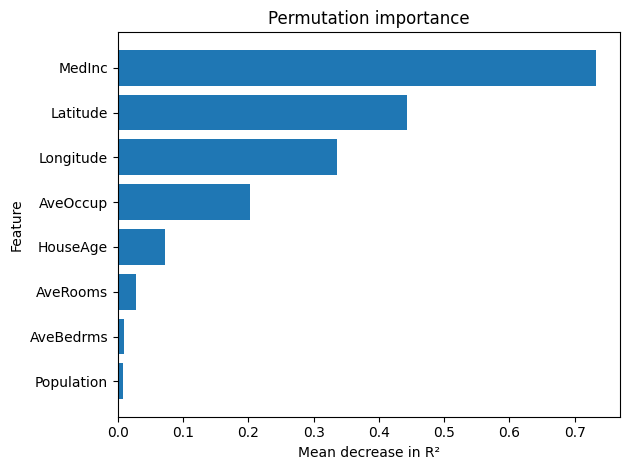


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


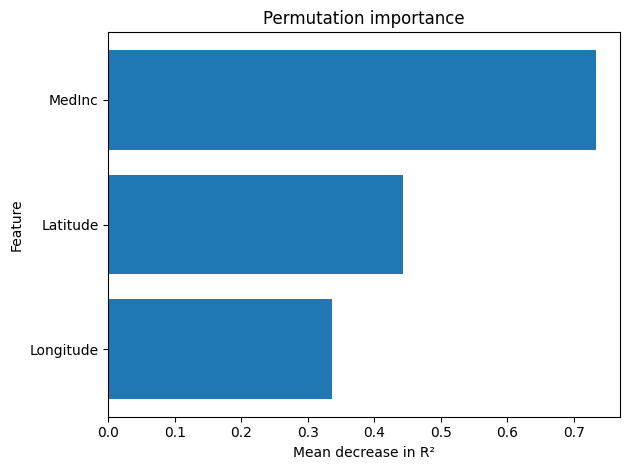


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


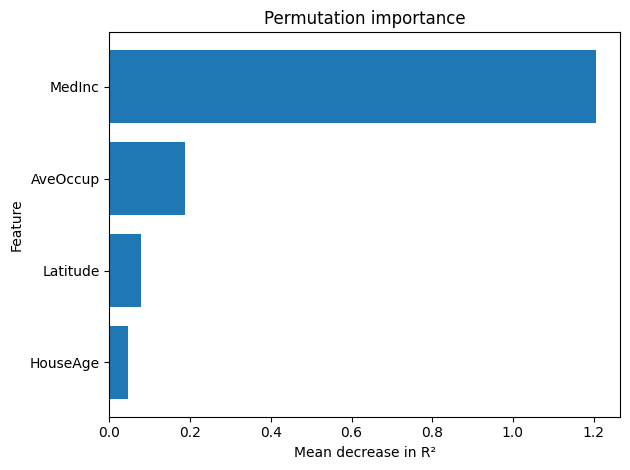

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [26]:
# CHECK — round 2
# To rerun this check, rerun the round 2 paste cell first: it checks whatever was pasted last
# "is" asks whether two names hold the very same function: if so, nothing new was pasted
if "importance_chart" not in globals() or importance_chart is globals().get("importance_chart_r1"):
    print("Paste the AI's round 2 importance_chart function in the cell above first, "
          "keeping that name, and run that cell.")
else:
    importance_chart_r2 = importance_chart      # kept, so the round 3 check can tell the two apart
    check_importance_chart(importance_chart_r2)

No round 3.

In [27]:
# Round 3 only: paste the importance_chart function from round 3 here, then run the check below.
# Paste only the function: if the AI also wrote example data or fitted a model, leave it out.

In [28]:
# CHECK — round 3 (only if you need one)
# To rerun this check, rerun the round 3 paste cell first: it checks whatever was pasted last
if "importance_chart" not in globals() or any(
        importance_chart is globals().get(name) for name in ("importance_chart_r1", "importance_chart_r2")):
    print("No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise "
          "paste round 3's importance_chart in the cell above, keeping that name, and run that cell.")
else:
    check_importance_chart(importance_chart)

No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise paste round 3's importance_chart in the cell above, keeping that name, and run that cell.


### Checking log

| Round | What I checked | How | What I found |
|---|---|---|---|
| 1 | Feature names, order, scores and refits | I compared the function's permutation call with Step 3 and ran the supplied check at k = 8 and 3. I also ran its comparison on the depth-6 tree at k = 4. | Both calls used the fitted model and the same evaluation rows, 10 shuffles and seed 42. The function specified R² explicitly, which is Step 3's default for this regressor. Every score differed by 0%, including Population at 0.0080. The forest-fit counter stayed at zero. |
| 2 | Whether the new k check or tie rule changed the scores | I compared the revised permutation call with Step 3 again. Both scored the supplied rows using R² with 10 repeats and seed 42. I reran all three comparisons. | Every row matched again. The forest's top three were MedInc, Latitude and Longitude. The other tree, tested on 500 rows with the columns reversed, ranked MedInc, AveOccup, Latitude and HouseAge highest. Every reported difference was 0%, and there were zero forest refits. |
| Chart | Bar order, labels and lengths | I compared the top-to-bottom labels and bar lengths with the returned rankings. | For k = 3, MedInc was on top at 0.7329, Latitude followed at 0.4427 and Longitude was third at 0.3361. On the eight-bar chart Population was last at 0.0080. The axis shows mean decrease in R². |

### Critique

Round 1 chose how to resolve ties without being asked:

```python
ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)
```

I would keep the stable sort. If two features tie at the cutoff, taking the one that appears first in the supplied DataFrame gives me a reproducible rule. I also asked for a range check because the original `.head(-1)` would quietly return every row except the last.

The final function computes and ranks the importances with these lines:

```python
scores = permutation_importance(model, X, y, scoring="r2", n_repeats=10, random_state=42)
ranking = pd.DataFrame({"feature": X.columns, "importance": scores.importances_mean})
ranking = ranking.sort_values("importance", ascending=False, kind="stable").head(k).reset_index(drop=True)
```

For each feature, the function averages the loss in R² over ten shuffles, keeping the model and all the other columns fixed. Using the same test rows, score and seed as Step 3 gives the same mean losses. It pairs each unrounded loss with its column name before sorting, so taking the first k rows changes only which results are shown.

### Judgment

I stopped after round 2. Agreement on the second tree gives me a reason to trust the function with a new fitted regressor and a DataFrame in the column order it expects. If the function had quietly reused the forest or its original column labels, that test would have caught it. I would choose a different score for a classifier where the question concerns ranking above-median properties by probability.

I would ask AI to draft a routine chart like this when I can specify the measure and check the bars against a calculation I trust. I would write the scoring step myself if the question called for a different shuffle, such as moving latitude and longitude together to preserve real coordinate pairs.

---

## Extension (Optional — 25 min): Partial Dependence Plots, and a Forest as a Classifier

**Partial dependence.** A partial dependence plot shows how the forest's prediction moves with one
feature, averaging over the values of all the others in the test rows. It shows the shape of a
relationship the forest found, curves and flat stretches included, which one OLS coefficient
cannot. Step 5 draws it for the tuned forest of Step 4, for `MedInc` and `AveOccup`
(`kind='average'`: the average curve only). Like importance, it describes the model, not a cause.

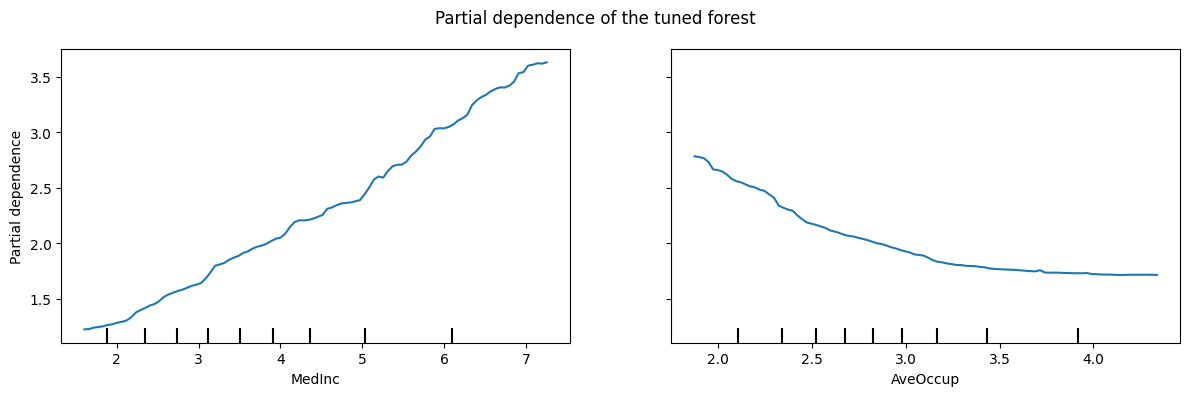

In [29]:
# GUIDED — run as-is (optional)
# Step 5: partial dependence of the tuned forest on two features
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    best_rf, X_test, features=['MedInc', 'AveOccup'], kind='average', ax=ax
)
plt.suptitle('Partial dependence of the tuned forest')
plt.tight_layout()
plt.savefig('figures/ch19_partial_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

**A forest as a classifier.** There is no starter code: write it in the cell below.

Turn the house value into a yes/no outcome, 1 when `y` is above its median (`np.median(y)`) and 0
otherwise (`.astype(int)` turns True/False into 1/0). Split it as Step 1 did (`test_size=0.2`,
`random_state=RANDOM_STATE`), with new names: `X_train_c`, `X_test_c`, `y_train_c` and `y_test_c`, and
`rf_clf` for the forest. `X_train`, `X_test`, `y_train`, `y_test` and `rf` must keep Step 1's and Step
2's meaning, because Steps 2-5 and the AI check read them: a check run after this cell would refuse
them. Fit `RandomForestClassifier(n_estimators=200,
random_state=RANDOM_STATE)` and, for comparison, Lab 17's logistic regression with the features
scaled first: `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`. Score each on the test rows by AUC, from Lab 18:
`roc_auc_score(y_true, scores)`, where the scores are `.predict_proba(X)[:, 1]`. Import the three
from `sklearn.ensemble`, `sklearn.linear_model` and `sklearn.metrics`. With these settings the
forest scores 0.9609 and the logistic regression 0.9082. Without the scaler, `LogisticRegression`
does not converge in 1,000 iterations on these features, which is why Lab 17 scaled them first.

**Your answers.** Does the forest beat logistic regression on AUC, and is the difference
practically significant? If you were building this for a real estate company, which would you
choose, and why? Consider accuracy, interpretability and the cost of keeping it running.

If you skip this task, leave its cell unrun, so your submitted notebook shows no error.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

above_median = (y > np.median(y)).astype(int)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, above_median, test_size=0.2, random_state=RANDOM_STATE
)
rf_clf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
auc = {}
for name, classifier in [('Random forest', rf_clf), ('Logistic regression', logit)]:
    classifier.fit(X_train_c, y_train_c)
    probabilities = classifier.predict_proba(X_test_c)[:, 1]
    auc[name] = roc_auc_score(y_test_c, probabilities)
    print(f'{name} test AUC: {auc[name]:.4f}')
print(f"AUC difference: {auc['Random forest'] - auc['Logistic regression']:.4f}")


Random forest test AUC: 0.9609
Logistic regression test AUC: 0.9082
AUC difference: 0.0527


The forest scored 0.9609 on test AUC, versus 0.9082 for logistic regression. For a randomly chosen above-median and at-or-below-median pair, the forest ranks the higher-value group first about 96 times out of 100, compared with about 91 for logistic regression. That difference could matter to a real estate company using the scores to decide which areas to research first.

I would use the forest for that ranking task and check how many worthwhile leads appeared in the number of areas the team could actually review. Logistic regression is cheaper to run and its coefficients are easier to explain. The forest's extra maintenance makes sense if the improvement at the team's review cutoff justifies the cost.

---
## Digital Portfolio: Your README

Copy the prompt below into Claude or ChatGPT. Fill in each [YOUR VALUE] from your own output
first, and do not quote a number this notebook did not print. **Do NOT ask the AI to write
Python code — only documentation.**

```
I need help writing a project README for my data science lab.
**Important Rule:** Do NOT generate any Python code for me.

**What I did in this lab:**
* Compared a single decision tree, OLS, Ridge and a random forest on
  California Housing: test R² 0.6228 for the tree, 0.5758
  for Ridge and 0.8046 for the forest
* Compared impurity (MDI) and permutation importance: Latitude scored
  0.0890 by MDI but 0.4427 by permutation
* Tuned the forest by cross-validation: test R² 0.8094
* Wrote my own prompt asking an AI for a feature-importance chart, went
  two rounds, and checked it against my numbers: both rounds matched the reference feature order and scores for the forest and the second tree, with zero forest refits

**Please write a README.md entry including:**
1. Project Title: Tree-Based Models: Random Forests
2. Objective: one sentence
3. Methodology: Bullet points of technical steps
4. Key Findings: Summary of results
Write it plainly, in the first person. No words like 'robust', 'comprehensive'
or 'leverage'. Use only the numbers I gave you.
```

---

## Submit this lab on GitHub

**Repository name for this lab:** `econ3916-lab19-random-forests`

**First time?** Read the **GitHub Setup** page in the Start Here module once,
start to finish. It assumes you have never used git and never seen GitHub.

1. On [github.com](https://github.com): **+** (top right) → **New repository**.
   Name it exactly `econ3916-lab19-random-forests`, tick **Add a README file**, and create it.
2. In Colab: **File → Save a copy in GitHub**. Choose `econ3916-lab19-random-forests`, branch `main`,
   commit message `Lab 19 submission`. This pushes the notebook, and the
   notebook's rendered output — charts included — is what is graded.
3. Open the repo on github.com, click `README.md`, then the pencil icon, and
   paste in the README you drafted from the prompt above. **Commit
   changes.** Check every number in it against your own output first: this
   goes out under your name.
4. On Canvas: in Colab use **File → Download → Download .ipynb**, upload that
   file to the assignment, and paste your repository URL in the **Comments**
   box beside the upload. Then click **Submit**. Do not use the Website URL
   tab: Canvas keeps one submission, so a URL sent on its own replaces your
   notebook.

No terminal, no token, nothing to install.